<a href="https://colab.research.google.com/github/ch1ral-is0mers/homework/blob/main/Semester_1/WIA1007/Tutorial_3/Tutorial_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 rows:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Dataset Overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


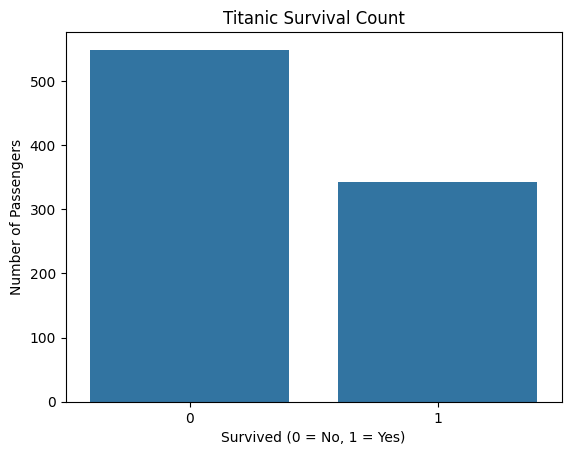


Data Quality:
Number of duplicate rows: 107
Total missing values: 869

Statistical Summary:


,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Number of selected features: 8
Features: ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']

Number of samples: 891

Data Types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Null Values Per Column:
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

Columns with Null Values:
['age', 'embarked', 'deck', 'embark_town']

Input Features:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'alone']

Target 

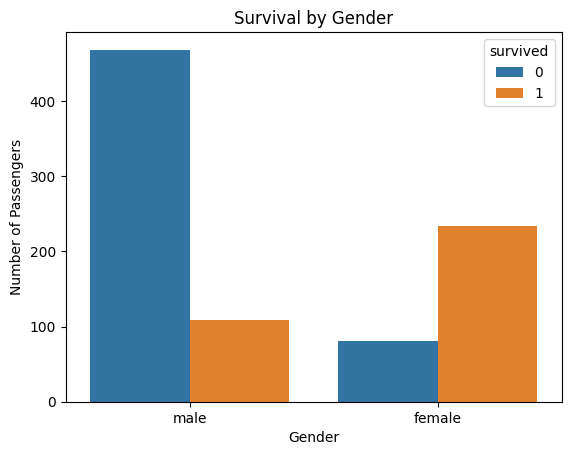

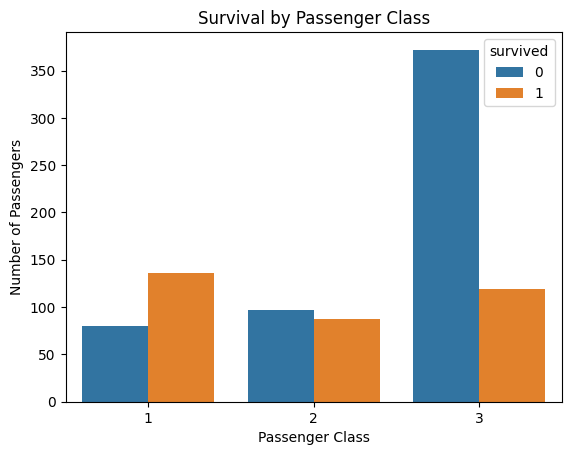

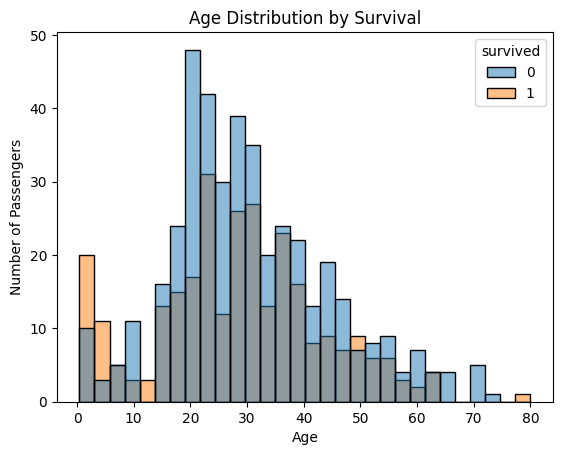

In [5]:

# WIA1007
# Tutorial 03
# Tang Jizhi
# 25007562

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(url)

# Q1 - Load and Visualize Dataset
print("First 5 rows:")
display(df.head())

print("\nDataset Overview:")
df.info()

# Visualize Survival Count
sns.countplot(data=df, x="survived")
plt.title("Titanic Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()

# Q2 - Evaluate Data Quality
print("\nData Quality:")
print("Number of duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())
print("\nStatistical Summary:")
display(df.describe())

# Q3 - Number of Features
feature_columns = [
    "pclass", "sex", "age", "sibsp",
    "parch", "fare", "embarked", "alone"
]

print("\nNumber of selected features:", len(feature_columns))
print("Features:", feature_columns)

# Q4 - Number of Samples / Observations
print("\nNumber of samples:", df.shape[0])

# Q5 - Data Types
print("\nData Types:")
print(df.dtypes)

# Q6 - Columns Containing Null Values
print("\nNull Values Per Column:")
print(df.isnull().sum())

print("\nColumns with Null Values:")
print(df.columns[df.isnull().any()].tolist())

# Q7 - Features and Target Output
X = df[feature_columns]
y = df["survived"]

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Output:")
print(y.name)

# Q8 - Find Missing Values and Rows
print("\nMissing Values:")
for column in df.columns:
    missing_rows = df.index[df[column].isnull()] + 1

    if len(missing_rows) > 0:
        print(f"\nColumn: {column}")
        print("Missing rows:", missing_rows.tolist())
        print("Number of missing values:", len(missing_rows))

# Q9 - Research Question and Visualization
print("\nResearch Question:")
print("Which factors are associated with Titanic passenger survival?")

# Survival by Gender
sns.countplot(data=df, x="sex", hue="survived")
plt.title("Survival by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.show()

# Survival by Passenger Class
sns.countplot(data=df, x="pclass", hue="survived")
plt.title("Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.show()

# Age Distribution
sns.histplot(data=df, x="age", hue="survived", bins=30,
             multiple="layer")
plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.show()
